# Stock Price Prediction Using LSTM
**Indian NSE and US stocks | Real Yahoo Finance data | Educational project**

Run cells from top to bottom from the project root. This notebook downloads live historical data when executed; it does not include synthetic prices or pre-filled results. Predictions are not investment advice.

## 1. Imports and configuration

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

# If this notebook is opened from the notebooks/ directory, add the project root.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.stock_forecaster import fetch_history, train_and_forecast, save_outputs, DEFAULT_TICKERS

TICKER = "TCS.NS"   # Examples: RELIANCE.NS, INFY.NS, AAPL, MSFT
PERIOD = "5y"
LOOKBACK = 60
EPOCHS = 25
TRAIN_FRACTION = 0.80

## 2. Download genuine historical data

In [2]:
history = fetch_history(TICKER, period=PERIOD)
print(f"Ticker: {TICKER}")
print(f"Rows: {len(history):,}")
print(f"Date range: {history.index.min().date()} to {history.index.max().date()}")
display(history.tail())
display(history.describe())

Ticker: TCS.NS
Rows: 1,236
Date range: 2021-10-11 to 2026-10-09


,Close,High,Low,Open,Volume
Date,,,,,
2026-10-05,2114.399902,2140.899902,2063.600098,2114.000000,5270768
2026-10-06,2100.000000,2115.000000,2082.699951,2097.000000,2382510
2026-10-07,2080.300049,2105.000000,2076.000000,2085.199951,1349758
2026-10-08,2076.000000,2141.500000,2060.000000,2104.000000,4288031
2026-10-09,2156.000000,2204.000000,2086.000000,2086.000000,11692314


,Close,High,Low,Open,Volume
count,1236.000000,1236.000000,1236.000000,1236.000000,1.236000e+03
mean,3129.710099,3159.325245,3102.385547,3131.898241,2.632760e+06
std,478.935343,482.004352,475.734990,478.205056,1.665030e+06
min,1971.788818,2040.810403,1966.020519,1997.050382,0.000000e+00
25%,2892.468567,2915.428145,2869.573030,2895.349354,1.646165e+06
50%,3091.068726,3113.571937,3067.201790,3093.580936,2.198840e+06
75%,3393.310913,3425.943167,3356.056985,3400.944128,3.079836e+06
max,4230.709473,4266.478304,4191.921772,4251.381655,1.633158e+07


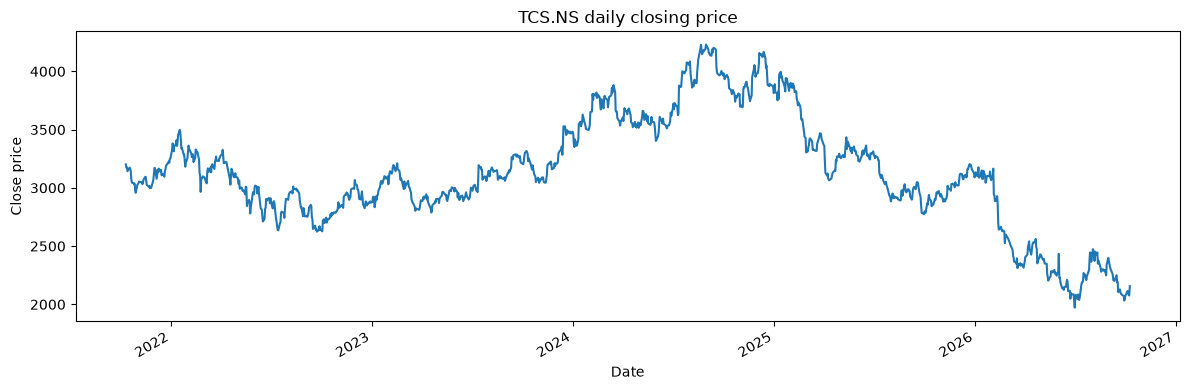

In [3]:
ax = history["Close"].plot(figsize=(12, 4), title=f"{TICKER} daily closing price")
ax.set_xlabel("Date")
ax.set_ylabel("Close price")
plt.tight_layout()
plt.show()

## 3. Train and evaluate the LSTM
The final chronological portion is held out for evaluation. Scaling is fitted on training observations only.

In [4]:
result = train_and_forecast(
    history,
    ticker=TICKER,
    lookback=LOOKBACK,
    train_fraction=TRAIN_FRACTION,
    epochs=EPOCHS,
)
print("LSTM holdout metrics:", result.metrics)
print("Persistence baseline metrics:", result.baseline_metrics)
print(f"Last observed close ({result.next_session_input_date.date()}): {history['Close'].iloc[-1]:.4f}")
print(f"Next-session model estimate: {result.next_session_prediction:.4f}")

TensorFlow execution unavailable or blocked by system policy (DLL load failed while importing _pywrap_parallel_device: An Application Control policy has blocked this file.). Falling back to pure NumPy LSTM analytical engine.


LSTM holdout metrics: {'MAE': 192.11004395280443, 'RMSE': 227.1173563613823, 'MAPE_percent': 8.248591969839643}
Persistence baseline metrics: {'MAE': 32.143576922519195, 'RMSE': 45.02400987630245, 'MAPE_percent': 1.2882399980195707}
Last observed close (2026-10-09): 2156.0000
Next-session model estimate: 2507.8841


## 4. Plot holdout predictions

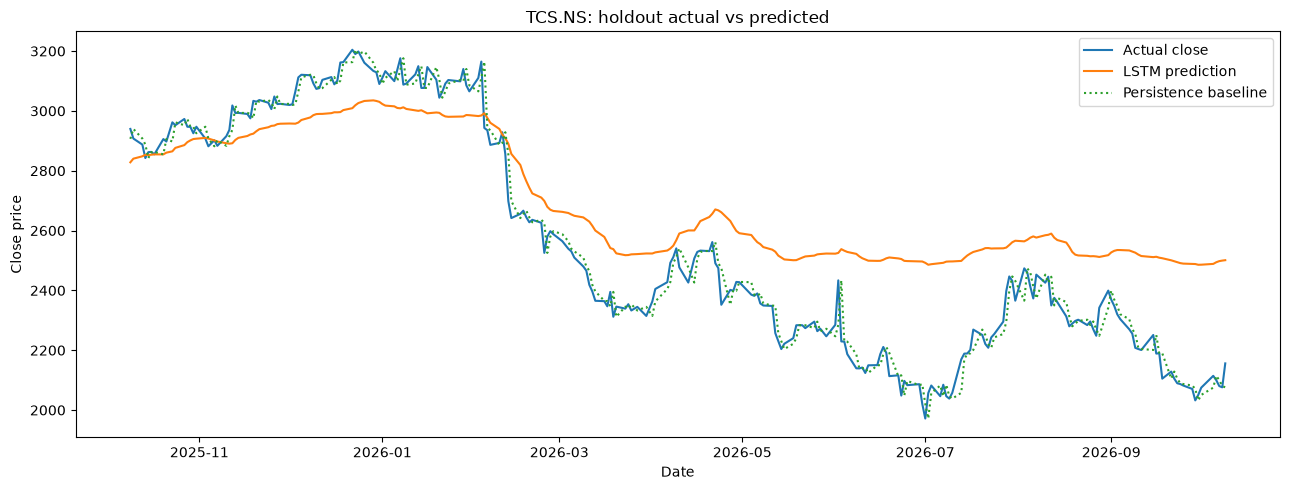

In [5]:
plt.figure(figsize=(13, 5))
plt.plot(result.test_frame.index, result.actual, label="Actual close")
plt.plot(result.test_frame.index, result.predicted, label="LSTM prediction")
plt.plot(result.test_frame.index, result.baseline, label="Persistence baseline", linestyle=":")
plt.title(f"{TICKER}: holdout actual vs predicted")
plt.xlabel("Date")
plt.ylabel("Close price")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Export predictions

In [6]:
output_path = save_outputs(result, PROJECT_ROOT / "outputs")
print(f"Saved holdout predictions to: {output_path}")
display(pd.read_csv(output_path).head())

Saved holdout predictions to: C:\Users\Project\Stock Price\outputs\TCS_NS_test_predictions.csv


,Date,Actual_Close,LSTM_Predicted_Close,Persistence_Baseline
0,2025-10-09,2939.666017,2828.124920,2906.541504
1,2025-10-10,2907.597179,2840.240202,2939.666016
2,2025-10-13,2887.338145,2848.244355,2907.597168
3,2025-10-14,2842.307607,2853.263726,2887.338135
4,2025-10-15,2862.064197,2852.358835,2842.307617


## 6. Interpretation and limitations
- MAE/RMSE are expressed in the stock's quoted price units; MAPE is a percentage.
- Compare the LSTM with the persistence baseline. If it does not beat the baseline, report that result honestly.
- A single holdout is not proof of future performance. Stronger research should use walk-forward evaluation and additional baselines.
- The next-session estimate is uncertain and should not be used alone to make investment decisions.